In [1]:
import perf
import pandas as pd

In [2]:
perf.system.info()

,cpu,core,numa,arch,platform,vendor,model,family,stepping,freq,L1i,L1d,L2,L3
0,0,0,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
1,1,4,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
2,2,8,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
3,3,12,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
4,4,16,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
5,5,20,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
6,6,28,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
7,7,29,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
8,8,30,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
9,9,31,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb


In [3]:
perf.system.tune()

,setting,path,before,after
0,aslr,/proc/sys/kernel/randomize_va_space,off,off
1,governor,/sys/devices/system/cpu/cpu*/cpufreq/scaling_g...,performance,performance
2,energy_performance_preference,/sys/devices/system/cpu/cpu*/cpufreq/energy_pe...,performance,performance
3,cpu_frequency,/sys/devices/system/cpu/cpu*/cpufreq/scaling_{...,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz
4,turbo,/sys/devices/system/cpu/intel_pstate/no_turbo,on,on
5,turbo_msr,/dev/cpu/*/msr,,on
6,boost,/sys/devices/system/cpu/cpufreq/boost,,on
7,rdpmc,/sys/devices/*/rdpmc,,
8,smt,/sys/devices/system/cpu/smt/control,on,on
9,nmi_watchdog,/proc/sys/kernel/nmi_watchdog,off,off


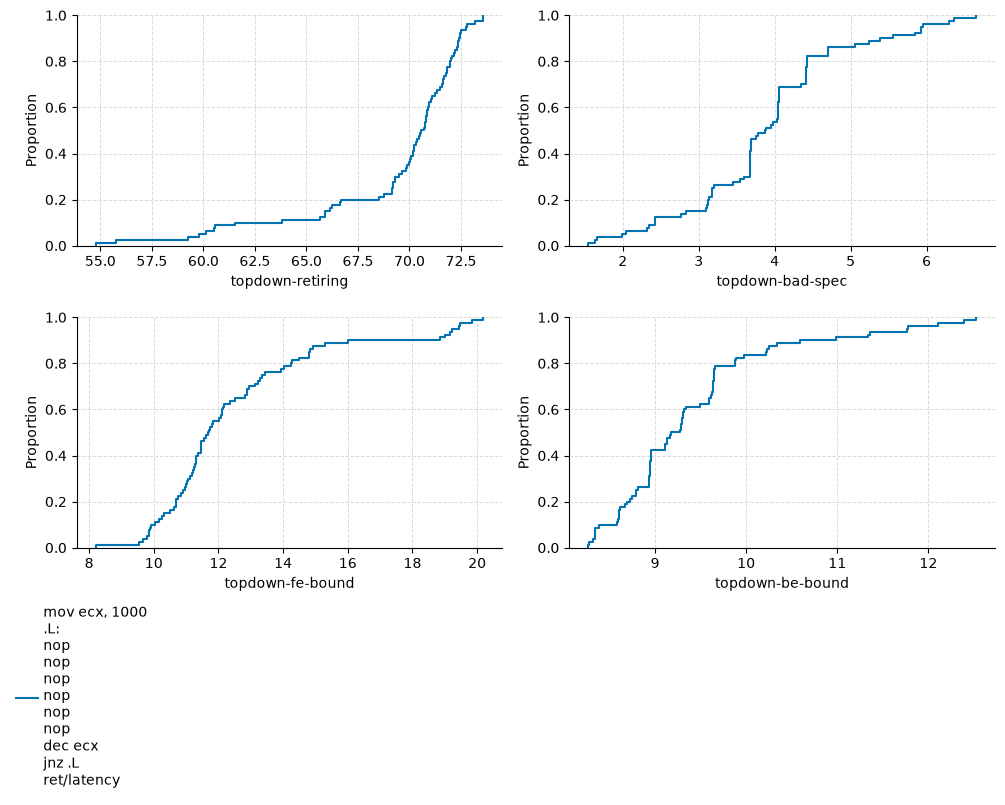

[]

In [4]:
NOPS = 6
top_code = f"mov ecx, 1000\n.L:\n" + "\n".join(["nop"] * NOPS) + "\ndec ecx\njnz .L\nret"
top = perf.benchmark(
    asm=top_code,
    mode=["latency"],
    event=["topdown*"],
    config={"samples": 60},
)
perf.plot(top, "ecdf", event=[c for c in top.columns if c.startswith("topdown-")])

In [5]:
frames = []
for n in [6, 12, 24, 48, 96]:
    code = f"mov ecx, 1000\n.L:\n" + "\n".join(["nop"] * n) + "\ndec ecx\njnz .L\nret"
    df = perf.benchmark(
        asm=code,
        mode=["latency"],
        event=["cycles", "instructions"],
        config={"samples": 60},
    ).reset_index()
    df["nops"] = n
    frames.append(df)
ipc = pd.concat(frames, ignore_index=True)
ipc["ipc"] = ipc["instructions"] / ipc["cycles"]
ipc.groupby("nops")["ipc"].agg(["median", "mean"]).round(2)

,median,mean
nops,,
6,6.42,6.49
12,6.30,6.34
24,5.94,5.98
48,5.43,5.55
96,5.31,5.30


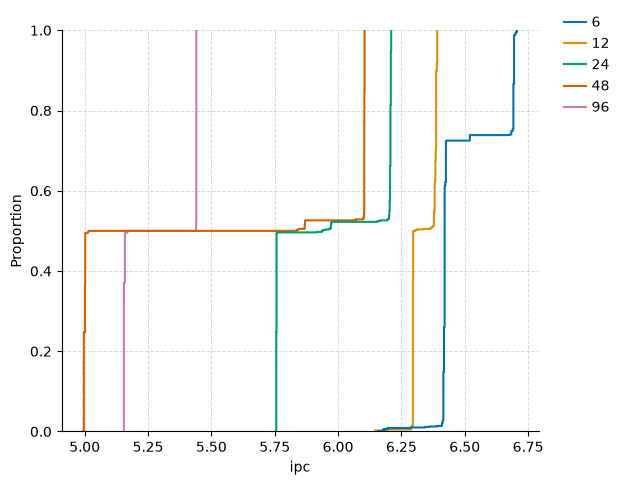

[]

In [6]:
perf.plot(ipc, "ecdf", event="ipc", groupby="nops")

In [7]:
ipc.groupby("nops")["ipc"].median().sort_values().tail(1)

nops
6    6.420546
Name: ipc, dtype: float64